In [ ]:
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
import matplotlib.pyplot as plt
import pandas as pd

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import normalize
from sklearn.decomposition import TruncatedSVD
from sklearn.decomposition import PCA



## Cleaning

In [2]:
prod_data = pd.read_csv("dataprep\product_level_description.csv")
prod_data

C:\Users\Meldb\AppData\Local\Temp\ipykernel_30008\1782759602.py:1: DtypeWarning: Columns (1) have mixed types. Specify dtype option on import or set low_memory=False.
  prod_data = pd.read_csv("dataprep\product_level_description.csv")


,Unnamed: 0,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,MissingCustomer
0,0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,False
1,1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,False
2,2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,False
3,3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,False
4,4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,False
...,...,...,...,...,...,...,...,...,...,...
530099,530099,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France,False
530100,530100,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France,False
530101,530101,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France,False
530102,530102,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France,False


In [3]:
print("NA in description col: ", prod_data["Description"].isna().sum())
print("unique vals in description col: ", prod_data["Description"].nunique())
print("NA in stock code col: ", prod_data["StockCode"].isna().sum())
print("unique vals in stock code col: ",prod_data["StockCode"].nunique()) 


NA in description col:  0
unique vals in description col:  4026
NA in stock code col:  0
unique vals in stock code col:  3922


In [4]:
# exploring stock codes with multiple descriptions
description_counts = (
    prod_data.groupby("StockCode")["Description"]
    .nunique()
    .sort_values(ascending=False)
)

# StockCodes with multiple descriptions
multiple_descriptions = description_counts[
    description_counts > 1
]

print("StockCodes with multiple descriptions:",
      len(multiple_descriptions))

print(multiple_descriptions.head(20))

StockCodes with multiple descriptions: 220
StockCode
23236     4
23196     4
17107D    3
23366     3
23203     3
23370     3
23126     3
23244     3
23413     3
23131     3
23535     3
22776     3
23209     3
22937     3
23396     3
23231     3
23240     3
22246     2
44235     2
22932     2
Name: Description, dtype: int64


In [5]:
# looking further into an example
prod_data[prod_data['StockCode'] == '23203']

,Unnamed: 0,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,MissingCustomer
174218,174218,552232,23203,JUMBO BAG DOILEY PATTERNS,11,2011-05-06 15:54:00,2.08,NaN,United Kingdom,True
174302,174302,552234,23203,JUMBO BAG DOILEY PATTERNS,9,2011-05-06 16:01:00,2.08,NaN,United Kingdom,True
174672,174672,552261,23203,JUMBO BAG DOILEY PATTERNS,10,2011-05-08 11:34:00,2.08,16807.0,United Kingdom,False
174862,174862,552268,23203,JUMBO BAG DOILEY PATTERNS,20,2011-05-08 11:49:00,2.08,14709.0,United Kingdom,False
174904,174904,552269,23203,JUMBO BAG DOILEY PATTERNS,1,2011-05-08 11:52:00,2.08,16121.0,United Kingdom,False
...,...,...,...,...,...,...,...,...,...,...
524539,524539,581219,23203,JUMBO BAG VINTAGE DOILY,3,2011-12-08 09:28:00,4.13,NaN,United Kingdom,True
526422,526422,581401,23203,JUMBO BAG VINTAGE DOILY,10,2011-12-08 13:43:00,2.08,17644.0,United Kingdom,False
526492,526492,581403,23203,JUMBO BAG VINTAGE DOILY,10,2011-12-08 13:46:00,2.08,13510.0,United Kingdom,False
528012,528012,581439,23203,JUMBO BAG VINTAGE DOILY,2,2011-12-08 16:30:00,4.13,NaN,United Kingdom,True


In [6]:
# using the stock code instead of description since it is more reliable (seen above, the description can be different for the same stock 
# code)

products = (
    prod_data.dropna(subset=["StockCode", "Description"])
    .groupby("StockCode")
    .agg(
        Description=("Description", lambda x: x.mode().iloc[0]), # most frequent description in each stock code
        Total_Quantity=("Quantity", "sum"),
        Average_Price=("UnitPrice", "mean"),
        Unique_Customers=("CustomerID", "nunique")
    )
    .reset_index()
)
products

,StockCode,Description,Total_Quantity,Average_Price,Unique_Customers
0,10002,INFLATABLE POLITICAL GLOBE,860,1.086620,40
1,10080,GROOVY CACTUS INFLATABLE,303,0.410909,19
2,10120,DOGGY RUBBER,193,0.210000,25
3,10123C,HEARTS WRAPPING TAPE,5,0.650000,3
4,10124A,SPOTS ON RED BOOKCOVER TAPE,16,0.420000,5
...,...,...,...,...,...
3917,gift_0001_20,Dotcomgiftshop Gift Voucher £20.00,10,16.708889,0
3918,gift_0001_30,Dotcomgiftshop Gift Voucher £30.00,7,25.075714,0
3919,gift_0001_40,Dotcomgiftshop Gift Voucher £40.00,3,33.566667,0
3920,gift_0001_50,Dotcomgiftshop Gift Voucher £50.00,4,41.890000,0


In [7]:
# cleaning and standardizing the description
import re
def clean_text(text):
    text = text.lower()
    text = re.sub(r"[£$€]", "", text) # Remove currency symbols
    text = re.sub(r"(\d+)\.00\b", r"\1", text) # Remove decimal zeros in prices
    text = re.sub(r"[^a-z0-9\s]", " ", text) # Remove other punctuation
    text = re.sub(r"\s+", " ", text) # Normalize whitespace
    return text.strip()

products["Description_Clean"] = (
    products["Description"].apply(clean_text)
)

products

,StockCode,Description,Total_Quantity,Average_Price,Unique_Customers,Description_Clean
0,10002,INFLATABLE POLITICAL GLOBE,860,1.086620,40,inflatable political globe
1,10080,GROOVY CACTUS INFLATABLE,303,0.410909,19,groovy cactus inflatable
2,10120,DOGGY RUBBER,193,0.210000,25,doggy rubber
3,10123C,HEARTS WRAPPING TAPE,5,0.650000,3,hearts wrapping tape
4,10124A,SPOTS ON RED BOOKCOVER TAPE,16,0.420000,5,spots on red bookcover tape
...,...,...,...,...,...,...
3917,gift_0001_20,Dotcomgiftshop Gift Voucher £20.00,10,16.708889,0,dotcomgiftshop gift voucher 20
3918,gift_0001_30,Dotcomgiftshop Gift Voucher £30.00,7,25.075714,0,dotcomgiftshop gift voucher 30
3919,gift_0001_40,Dotcomgiftshop Gift Voucher £40.00,3,33.566667,0,dotcomgiftshop gift voucher 40
3920,gift_0001_50,Dotcomgiftshop Gift Voucher £50.00,4,41.890000,0,dotcomgiftshop gift voucher 50


## Text Vectorization

In [10]:
# unigrams - 
tfidf_unigrams = TfidfVectorizer(
    stop_words="english",
    ngram_range=(1, 1),
    max_features=5000,
    min_df=2,
    max_df=0.90,
    sublinear_tf=True
)

X_unigrams = tfidf_unigrams.fit_transform(
    products["Description_Clean"]
)

In [11]:
# bigrams - 
tfidf_bigrams = TfidfVectorizer(
    stop_words="english",
    ngram_range=(2, 2),
    max_features=5000,
    min_df=2,
    max_df=0.90,
    sublinear_tf=True
)

X_bigrams = tfidf_bigrams.fit_transform(
    products["Description_Clean"]
)

In [12]:
# unigrams & bigrams
tfidf_combined = TfidfVectorizer(
    stop_words="english",
    ngram_range=(1, 2),
    max_features=5000,
    min_df=2,
    max_df=0.90,
    sublinear_tf=True
)

X_combined = tfidf_combined.fit_transform(
    products["Description_Clean"]
)

In [13]:
def run_clustering(
    X,
    k_values,
    experiment_name,
    sample_size=2000,
    n_init=10
):

    results = []
    labels_dict = {}

    # Normalize the feature matrix
    X_norm = normalize(X)

    for k in k_values:

        model = KMeans(
            n_clusters=k,
            random_state=42,
            n_init=n_init
        )

        labels = model.fit_predict(X_norm)

        # Calculate silhouette score
        score = silhouette_score(
            X_norm,
            labels,
            metric="cosine",
            sample_size=min(sample_size, X.shape[0]),
            random_state=42
        )

        results.append({
            "Experiment": experiment_name,
            "K": k,
            "Inertia": model.inertia_,
            "Silhouette": score
        })

        labels_dict[k] = labels

        print(
            f"K={k} | "
            f"Inertia={model.inertia_:.2f} | "
            f"Silhouette={score:.4f}"
        )

    results_df = pd.DataFrame(results)

    # Visualise inertia and silhouette
    fig, ax1 = plt.subplots(figsize=(10, 5))

    ax1.plot(
        results_df["K"],
        results_df["Inertia"],
        marker="o",
        color="steelblue"
    )

    ax1.set_xlabel("Number of Clusters (K)")
    ax1.set_ylabel("Inertia", color="steelblue")

    ax2 = ax1.twinx()

    ax2.plot(
        results_df["K"],
        results_df["Silhouette"],
        marker="s",
        color="darkorange"
    )

    ax2.set_ylabel("Silhouette Score", color="darkorange")

    plt.title(f"{experiment_name}: Elbow and Silhouette")
    plt.tight_layout()
    plt.show()

    return results_df, labels_dict

In [15]:
k_values = [10, 30, 50, 75, 100, 150]

K=10 | Inertia=3653.70 | Silhouette=0.0409
K=30 | Inertia=3361.29 | Silhouette=0.0898
K=50 | Inertia=3162.87 | Silhouette=0.1054
K=75 | Inertia=2967.79 | Silhouette=0.1301
K=100 | Inertia=2839.63 | Silhouette=0.1368
K=150 | Inertia=2631.57 | Silhouette=0.1555


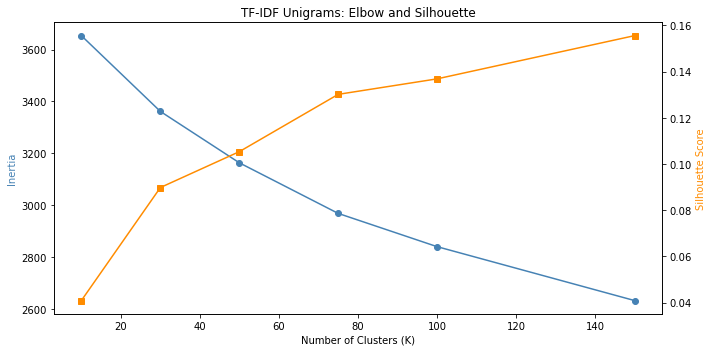

In [23]:
results_unigrams, labels_unigrams = run_clustering(
    X_unigrams,
    k_values,
    "TF-IDF Unigrams"
)

K=10 | Inertia=3307.51 | Silhouette=0.0325
K=30 | Inertia=3127.94 | Silhouette=0.0705
K=50 | Inertia=2995.30 | Silhouette=0.0998
K=75 | Inertia=2861.04 | Silhouette=0.1207
K=100 | Inertia=2738.07 | Silhouette=0.1484
K=150 | Inertia=2508.31 | Silhouette=0.1972


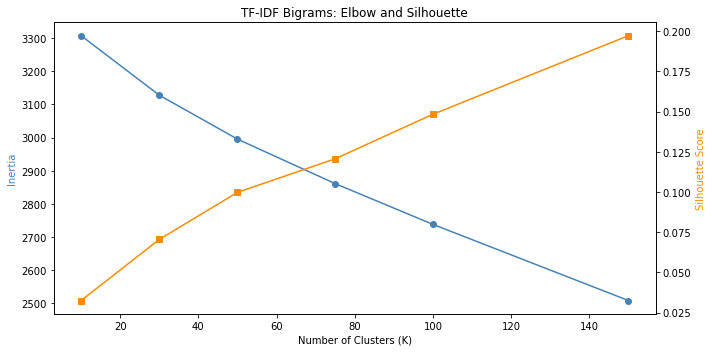

In [16]:
results_bigrams, labels_bigrams = run_clustering(
    X_bigrams,
    k_values,
    "TF-IDF Bigrams"
)

K=10 | Inertia=3752.20 | Silhouette=0.0237
K=30 | Inertia=3497.96 | Silhouette=0.0655
K=50 | Inertia=3343.51 | Silhouette=0.0850
K=75 | Inertia=3207.35 | Silhouette=0.1057
K=100 | Inertia=3084.61 | Silhouette=0.1193
K=150 | Inertia=2875.74 | Silhouette=0.1484


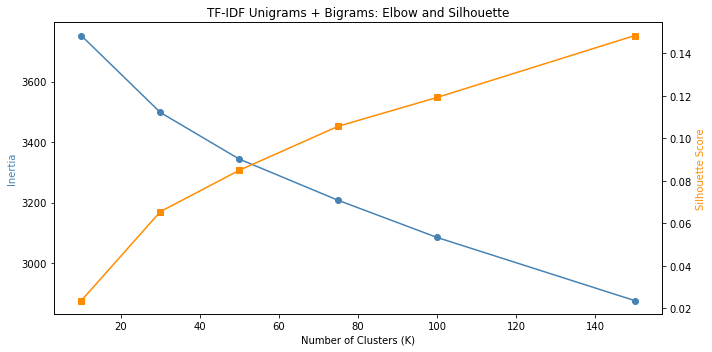

In [17]:
results_combined, labels_combined = run_clustering(
    X_combined,
    k_values,
    "TF-IDF Unigrams + Bigrams"
)

In [26]:
tfidf_comparison = pd.concat([
    results_unigrams,
    results_bigrams,
    results_combined
   ], ignore_index=True)

print(
    tfidf_comparison.sort_values(
        "Silhouette",
        ascending=False
    )
)

                   Experiment    K      Inertia  Silhouette
11             TF-IDF Bigrams  150  2508.305512    0.197235
5             TF-IDF Unigrams  150  2631.571254    0.155543
10             TF-IDF Bigrams  100  2738.071667    0.148365
17  TF-IDF Unigrams + Bigrams  150  2875.742867    0.148364
4             TF-IDF Unigrams  100  2839.629786    0.136836
3             TF-IDF Unigrams   75  2967.786951    0.130139
9              TF-IDF Bigrams   75  2861.043146    0.120670
16  TF-IDF Unigrams + Bigrams  100  3084.613444    0.119268
15  TF-IDF Unigrams + Bigrams   75  3207.352403    0.105718
2             TF-IDF Unigrams   50  3162.872408    0.105362
8              TF-IDF Bigrams   50  2995.298850    0.099798
1             TF-IDF Unigrams   30  3361.293243    0.089821
14  TF-IDF Unigrams + Bigrams   50  3343.507222    0.085037
7              TF-IDF Bigrams   30  3127.941333    0.070521
13  TF-IDF Unigrams + Bigrams   30  3497.960936    0.065550
0             TF-IDF Unigrams   10  3653

K=100 | Inertia=2738.07 | Silhouette=0.1484
K=125 | Inertia=2622.85 | Silhouette=0.1691
K=150 | Inertia=2508.31 | Silhouette=0.1972
K=175 | Inertia=2405.48 | Silhouette=0.2187
K=200 | Inertia=2319.23 | Silhouette=0.2300
K=250 | Inertia=2146.50 | Silhouette=0.2636
K=300 | Inertia=1997.47 | Silhouette=0.2845


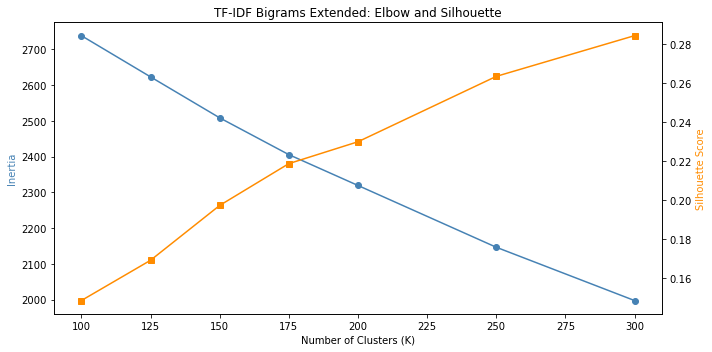

In [27]:
k_values_extended = [100, 125, 150, 175, 200, 250, 300]
results_bigrams_extended, labels_bigrams_extended = run_clustering(
    X_bigrams,
    k_values_extended,
    "TF-IDF Bigrams Extended"
)

In [28]:
products["Bigram_Cluster_300"] = labels_bigrams_extended[300]

cluster_sizes = (
    products["Bigram_Cluster_300"]
    .value_counts()
    .sort_values(ascending=False)
)

print("Number of clusters:", len(cluster_sizes))
print("\nLargest clusters:")
print(cluster_sizes.head(15))

print("\nSmallest clusters:")
print(cluster_sizes.tail(15))

print("\nCluster size statistics:")
print(cluster_sizes.describe())

Number of clusters: 300

Largest clusters:
4      1943
13       42
21       37
14       33
17       32
72       29
1        25
5        22
16       21
40       21
20       21
59       19
67       18
157      17
235      15
Name: Bigram_Cluster_300, dtype: int64

Smallest clusters:
273    2
243    2
115    2
288    2
275    2
36     2
12     2
0      2
168    2
287    2
291    2
200    2
179    2
286    2
246    2
Name: Bigram_Cluster_300, dtype: int64

Cluster size statistics:
count     300.000000
mean       13.073333
std       111.921383
min         2.000000
25%         4.000000
50%         5.000000
75%         8.000000
max      1943.000000
Name: Bigram_Cluster_300, dtype: float64


## Using LSA

In [18]:
svd_50 = TruncatedSVD(
    n_components=50,
    random_state=42
)

X_lsa_50 = svd_50.fit_transform(X_bigrams)

print("Original dimensions:", X_bigrams.shape)
print("Reduced dimensions:", X_lsa_50.shape)

print(
    "Explained variance:",
    svd_50.explained_variance_ratio_.sum()
)

Original dimensions: (3922, 2040)
Reduced dimensions: (3922, 50)
Explained variance: 0.16582024665617237


K=50 | Inertia=1576.81 | Silhouette=0.3041
K=100 | Inertia=1030.54 | Silhouette=0.3996
K=150 | Inertia=765.35 | Silhouette=0.4701
K=200 | Inertia=605.04 | Silhouette=0.5080
K=250 | Inertia=480.85 | Silhouette=0.5545
K=300 | Inertia=384.79 | Silhouette=0.5844


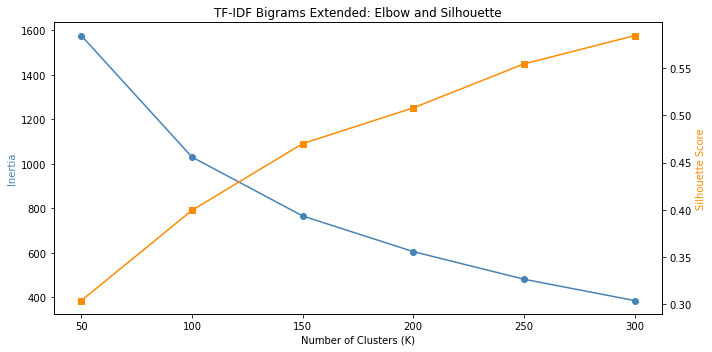

In [20]:
k_values = [50, 100, 150, 200, 250, 300]
results_svm_50, labels_svm_50 = run_clustering(
    X_lsa_50,
    k_values,
    "TF-IDF LSA 50 Bigrams"
)

## Creating Final model

In [25]:
# Normalise LSA representation
X_final = normalize(X_lsa_50)

# Final K-Means model
final_model = KMeans(
    n_clusters=150,
    random_state=42,
    n_init=10
)

# Fit model and generate labels
final_labels = final_model.fit_predict(X_final)

# Assign clusters to products
products["Product_Cluster"] = final_labels

print("Number of products:", len(products))
print("Number of clusters:", products["Product_Cluster"].nunique())

Number of products: 3922
Number of clusters: 150


In [26]:
final_silhouette = silhouette_score(
    X_final,
    final_labels,
    metric="cosine",
    sample_size=min(2000, X_final.shape[0]),
    random_state=42
)

print("Final inertia:", final_model.inertia_)
print("Final silhouette:", final_silhouette)

Final inertia: 765.3463589761469
Final silhouette: 0.47013871672233554


Explained variance: 0.1567


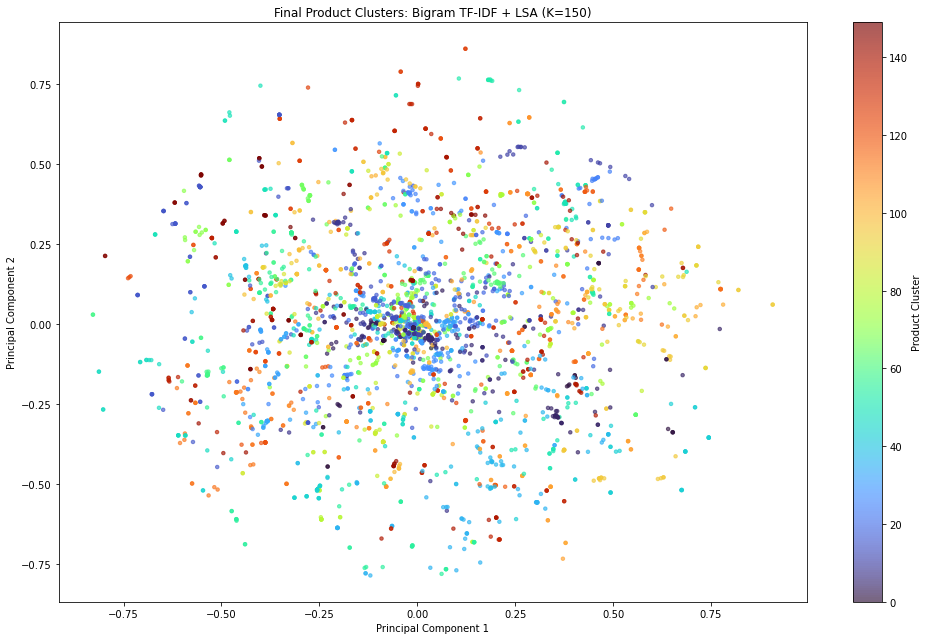

In [28]:
# visualize using PCA
pca = PCA(
    n_components=2,
    random_state=42
)

X_pca = pca.fit_transform(X_final)

print(
    "Explained variance:",
    round(pca.explained_variance_ratio_.sum(), 4)
)
plt.figure(figsize=(14, 9))

scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=final_labels,
    cmap="turbo",
    s=12,
    alpha=0.65
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Final Product Clusters: Bigram TF-IDF + LSA (K=150)")

plt.colorbar(scatter, label="Product Cluster")

plt.tight_layout()
plt.show()

In [29]:
cluster_sizes = (
    products["Product_Cluster"]
    .value_counts()
    .sort_values(ascending=False)
)

print("Largest clusters:")
print(cluster_sizes.head(15))

print("\nSmallest clusters:")
print(cluster_sizes.tail(15))

print("\nCluster size statistics:")
print(cluster_sizes.describe())

Largest clusters:
2      484
5       78
7       77
21      58
12      54
75      53
15      47
36      47
11      45
55      42
13      41
45      40
31      39
43      37
113     37
Name: Product_Cluster, dtype: int64

Smallest clusters:
82     10
61      9
124     9
103     9
148     8
111     8
143     8
139     7
90      7
140     7
129     7
127     6
133     6
146     5
6       5
Name: Product_Cluster, dtype: int64

Cluster size statistics:
count    150.000000
mean      26.146667
std       39.636500
min        5.000000
25%       13.000000
50%       22.000000
75%       30.000000
max      484.000000
Name: Product_Cluster, dtype: float64


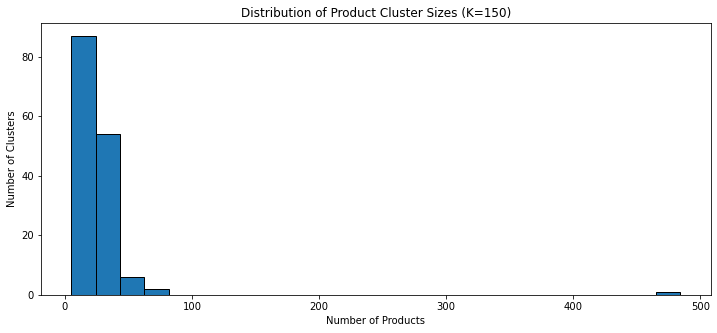

In [30]:
plt.figure(figsize=(12, 5))

plt.hist(
    cluster_sizes,
    bins=25,
    edgecolor="black"
)

plt.xlabel("Number of Products")
plt.ylabel("Number of Clusters")
plt.title("Distribution of Product Cluster Sizes (K=150)")

plt.show()

In [31]:
def inspect_product_cluster(products, cluster_id, n=30):

    cluster_products = products[
        products["Product_Cluster"] == cluster_id
    ]

    print(f"\nCLUSTER {cluster_id}")
    print("-" * 50)

    print("Number of products:", len(cluster_products))

    print("\nProduct descriptions:")

    for description in cluster_products["Description"].head(n):
        print("-", description)

In [40]:
inspect_product_cluster(products, 13)


CLUSTER 13
--------------------------------------------------
Number of products: 41

Product descriptions:
- MIDNIGHT BLUE COPPER FLOWER NECKLAC
- MIDNIGHT BLUE PAIR HEART HAIR SLIDE
- MIDNIGHT BLUE GLASS/SILVER BRACELET
- MIDNIGHT BLUE CRYSTAL DROP EARRINGS
- BLACK CRYSTAL DROP EARRINGS
- GREEN CRYSTAL DROP EARRINGS
- PURPLE CRYSTAL DROP EARRINGS
- AMBER CRYSTAL DROP EARRINGS
- MIDNIGHT BLUE DROP CRYSTAL NECKLACE
- BLACK DROP CRYSTAL NECKLACE
- MIDNIGHT BLUE VINTAGE EARRINGS
- SILVER AND BLACK ORBIT NECKLACE
- SILVER M.O.P ORBIT DROP EARRINGS
- GOLD M.O.P ORBIT DROP EARRINGS
- SILVER BLACK ORBIT DROP EARRINGS
- SILVER M.O.P ORBIT BRACELET
- GOLD M.O.P ORBIT BRACELET
- SILVER BLACK ORBIT BRACELET
- EDWARDIAN DROP EARRINGS JET BLACK
- BLACK VINT ART DEC CRYSTAL NECKLACE
- SILVER DROP EARRINGS WITH FLOWER
- SILVER HOOP EARRINGS WITH FLOWER
- CLASSIC DIAMANTE EARRINGS JET
- AMBER 3 BEAD DROP EARRINGS
- AMETHYST 3 BEAD DROP EARRINGS
- BLACK 3 BEAD DROP EARRINGS
- AMBER DROP EARRINGS W LO

In [34]:
cluster_summary = (
    products.groupby("Product_Cluster")
    .agg(
        Number_of_Products=("StockCode", "count"),
        Average_Price=("Average_Price", "mean"),
        Total_Quantity=("Total_Quantity", "sum"),
        Unique_Customers=("Unique_Customers", "sum"),
        Example_Products=(
            "Description",
            lambda x: " | ".join(x.head(5))
        )
    )
    .reset_index()
)

cluster_summary = cluster_summary.sort_values(
    "Number_of_Products",
    ascending=False
)

cluster_summary.head(20)

,Product_Cluster,Number_of_Products,Average_Price,Total_Quantity,Unique_Customers,Example_Products
2,2,484,43.447645,712920,30159,INFLATABLE POLITICAL GLOBE | GROOVY CACTUS IN...
5,5,78,2.312213,224859,6386,PINK TALL PORCELAIN T-LIGHT HOLDER | WHITE TA...
7,7,77,3.562777,226099,11421,RED RETROSPOT LUGGAGE TAG | RED RETROSPOT PURS...
21,21,58,3.390107,17258,1195,POP ART PUSH DOWN RUBBER | TEATIME PUSH DOWN ...
12,12,54,2.955933,22369,1295,SET/10 RED POLKADOT PARTY CANDLES | SET/10 PIN...
75,75,53,2.780286,33369,1895,BIRD BOX CHRISTMAS TREE DECORATION | GREEN GOO...
36,36,47,4.325446,55677,2648,PINK BLUE FELT CRAFT TRINKET BOX | PINK CREAM ...
15,15,47,4.161092,70713,4239,PIECE OF CAMO STATIONERY SET | ROSE FLOWER CAN...
11,11,45,2.387742,115749,5610,BEWARE OF THE CAT METAL SIGN | COOK WITH WINE...
55,55,42,3.400736,58789,3066,LARGE CAMPHOR WOOD FIELD MUSHROOM | LARGE TA...


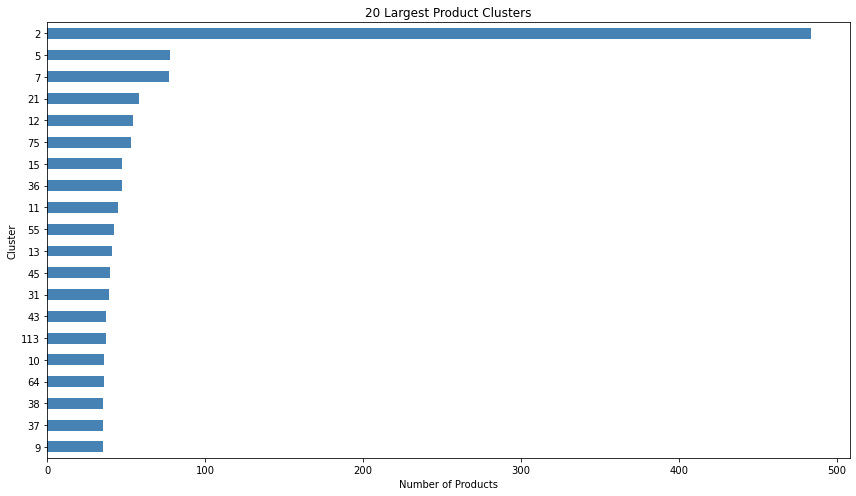

In [35]:
top_clusters = (
    products["Product_Cluster"]
    .value_counts()
    .head(20)
    .sort_values()
)

plt.figure(figsize=(12, 7))

top_clusters.plot(
    kind="barh",
    color="steelblue"
)

plt.xlabel("Number of Products")
plt.ylabel("Cluster")
plt.title("20 Largest Product Clusters")

plt.tight_layout()
plt.show()